# Ball Carrier Open Space

BCOS estimates the probability that the carrier reaches a target location before defenders control it. The resulting field shows where the carrier has open space under the modeled motion assumptions. **own derivation**

## Model and inputs

The competing-risk solver tracks carrier arrival probability S and defender interception probabilities P_i at each target. At each time step, U=clip(1−S−Σ_i P_i,0,1); dS=U h_BC dt and dP_i=U h_i dt. Thus each defender contributes a cause-specific probability while competing through the shared remaining mass. The reported open-space field is carrier arrival probability at the integration horizon. Inputs include carrier/defender positions and velocities, a target grid, motion/rotation parameters, and numerical step settings. **own derivation**.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

The modeled concept is Ball Carrier Open Space (BCOS), a formalization inspired by Bandara et al. [@bandara2025bcos]. Competing-risk equations follow the implementation; **own derivation**.

This solver is a PRESS competing-risk formalization of carrier open space using tracked positions and velocities. It is inspired by the BCOS concept but does not reproduce Bandara et al.’s camera-visible-area calculation from event freeze frames. **own derivation; model scope**


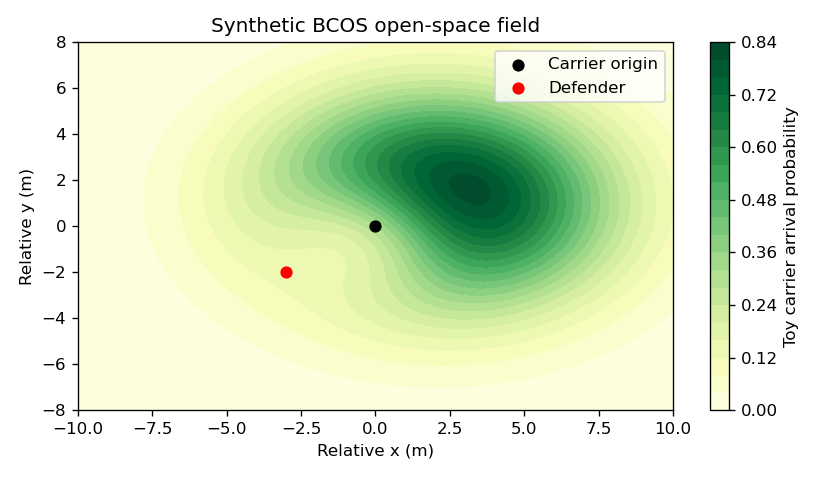

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Toy probability field demonstrating the output shape of BCOS.
x,y=np.meshgrid(np.linspace(-10,10,61),np.linspace(-8,8,49)); carrier=np.exp(-((x-2)**2/30+(y-1)**2/20)); defender=.72*np.exp(-((x+1)**2/15+(y+1)**2/12)); open_space=np.clip(carrier*(1-defender),0,1)
fig,ax=plt.subplots(figsize=(7,4)); im=ax.contourf(x,y,open_space,levels=20,cmap="YlGn"); fig.colorbar(im,ax=ax,label="Toy carrier arrival probability"); ax.scatter([0], [0], c="black",s=40,label="Carrier origin"); ax.scatter([-3],[-2],c="red",s=40,label="Defender"); ax.set(xlabel="Relative x (m)",ylabel="Relative y (m)",title="Synthetic BCOS open-space field"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_10_bcos.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))